# Semana 10 — Horizonte Rodante (RH): gestión de una pesquería

Esta sesión estudia el **horizonte rodante (RH)** en un MDP de **horizonte infinito descontado**. El caso es una pesquería: cada temporada se decide cuánto pescar, sabiendo que lo que no se pesca hoy se reproduce y puede pescarse después.

Se comparan:

- la política óptima, obtenida con iteración de valor (VI);
- políticas RH con diferentes longitudes de ventana $H$ y diferentes funciones terminales $\hat g$.

El valor de todas las políticas se calcula de forma exacta con el sistema lineal $(I-\gamma P^\pi)V^\pi = r^\pi$.


---
## Fundamentos

### El problema de horizonte infinito

El valor óptimo cumple la ecuación de Bellman

$$
V^*(s)
=
\max_a
\left[
r(s,a)
+
\gamma
\sum_{s'}
P(s'|s,a)\,
V^*(s')
\right],
$$

y el valor de una política estacionaria $\pi$ se obtiene resolviendo

$$
(I-\gamma P^\pi)\,V^\pi = r^\pi .
$$

### Horizonte rodante

En cada período:

1. se observa el estado actual $s$;
2. se resuelve un problema de $H$ períodos con valor terminal $\hat g$ al final;
3. se ejecuta **solo la primera acción**;
4. se observa el nuevo estado y se vuelve a resolver.

Dentro de la ventana:

$$
V_{k}(s)
=
\max_a
\left[
r(s,a)
+
\gamma
\sum_{s'}
P(s'|s,a)\,
V_{k+1}(s')
\right],
\qquad
V_{H}(s)=\hat g(s).
$$

Como el problema es estacionario, la ventana es la misma en todos los períodos. Su primera decisión para cada estado define una política estacionaria $\pi_{RH}$, cuyo valor también se calcula con el sistema lineal.

### La función terminal $\hat g$

En horizonte infinito no hay un valor terminal real: el problema no termina. Lo que $\hat g$ debería representar es el valor de seguir operando desde el final de la ventana, es decir, $V^*$. Si $\hat g = V^*$, el RH toma la decisión óptima con cualquier $H$, incluso $H=1$.

Cuando $\hat g$ es una mala aproximación aparecen dos sesgos:

- **Miopía:** con $H$ pequeño se ignoran consecuencias lejanas.
- **Efecto de borde:** con $\hat g\equiv 0$, los peces que quedan en el agua al final de la ventana "no valen nada", y el modelo tiende a pescarlo todo antes del borde.

| Símbolo | Significado |
|:---:|:---|
| $\gamma$ | factor de descuento ($0.99$) |
| $H$ | longitud de la ventana de planeación del RH |
| $\hat g(s)$ | función terminal que el RH pone al final de la ventana |
| $V^*(s)$ | valor óptimo |
| $\pi_{RH}$ | política que resulta de aplicar el RH en cada período |

In [1]:
# Ejecutar esta celda si jmarkov no está instalado.
!pip install jmarkov

In [2]:
import math

import numpy as np
import matplotlib.pyplot as plt

from jmarkov.mdp.dtmdp import dtmdp
from jmarkov.sdp.dtsdp import dtsdp

---
## Problema: Cooperativa pesquera Bahía Azul

La cooperativa Bahía Azul explota un banco de peces en una bahía cerrada. Al inicio de cada temporada observa el **stock** $s\in\{0,1,\dots,30\}$ (en toneladas) y decide una **cuota de pesca** $q\in\{0,1,\dots,5\}$ toneladas. Si el stock es menor que la cuota, se pesca todo lo que hay: la pesca efectiva es $h=\min(q,s)$.

**Retorno de la temporada** (en millones de pesos):

$$
r(s,q) = \underbrace{P\,h - d\,h^2}_{\text{ventas}} \;-\; \underbrace{\Big(c_0 + c_1\,\frac{K-s}{K}\Big)\,h}_{\text{costo de pesca}}
$$

- $P=10$: precio por tonelada.
- $d=0.8$: el precio cae cuando se lleva mucho pescado al mercado.
- $c_0=2$, $c_1=6$: pescar cuesta más cuando hay pocos peces, porque cuesta más encontrarlos.

**Dinámica del stock.** Después de pescar quedan $x=s-h$ toneladas, que se reproducen. Las crías siguen una distribución de Poisson con media

$$
\lambda(x) = \lambda_0 + r\,x\left(1-\frac{x}{K}\right),
$$

con capacidad de carga $K=30$, tasa de crecimiento $r=0.25$ e inmigración $\lambda_0=0.3$ (algunos peces llegan de afuera aunque la bahía esté vacía). El stock siguiente es $s'=\min(K,\ x+\text{crías})$.

El crecimiento es **lento**: con un stock de 15 toneladas nacen en promedio menos de 2.2 toneladas por temporada. Una sobrepesca tarda muchas temporadas en corregirse.

**Criterio:** la cooperativa opera indefinidamente con factor de descuento $\gamma=0.99$ por temporada.

In [3]:
# Parámetros del problema

CAPACIDAD_CARGA = 30          # K: stock máximo (toneladas)
CUOTA_MAXIMA = 5

NUMERO_ESTADOS = CAPACIDAD_CARGA + 1   # stock 0, 1, ..., 30
NUMERO_ACCIONES = CUOTA_MAXIMA + 1     # cuota 0, 1, ..., 5

PRECIO = 10.0
SATURACION = 0.8
COSTO_BASE = 2.0
COSTO_ESCASEZ = 6.0

TASA_CRECIMIENTO = 0.25
INMIGRACION = 0.3

GAMMA = 0.99

# Media de crías según el stock que queda después de pescar.
media_crias = np.zeros(NUMERO_ESTADOS)

for stock_restante in range(NUMERO_ESTADOS):

    media_crias[stock_restante] = (
        INMIGRACION
        + TASA_CRECIMIENTO
        * stock_restante
        * (1 - stock_restante / CAPACIDAD_CARGA)
    )

print("Media de crías para x = 0, 5, 10, 15, 20, 25, 30:")
print(np.round(media_crias[0:NUMERO_ESTADOS:5], 2))

Media de crías para x = 0, 5, 10, 15, 20, 25, 30:
[0.3  1.34 1.97 2.17 1.97 1.34 0.3 ]


---
## Construcción de $R$ y $P$

Una cuota mayor que el stock pesca todo lo que hay, así que no hay acciones infactibles. La probabilidad de que las crías superen la capacidad de carga se acumula en $s'=K$.

In [4]:
retornos = np.zeros((NUMERO_ESTADOS, NUMERO_ACCIONES))

# Una matriz de transición por acción.
transiciones = []

for cuota in range(NUMERO_ACCIONES):
    transiciones.append(np.zeros((NUMERO_ESTADOS, NUMERO_ESTADOS)))

for stock in range(NUMERO_ESTADOS):

    for cuota in range(NUMERO_ACCIONES):

        pesca = min(cuota, stock)
        stock_restante = stock - pesca

        costo_por_tonelada = (
            COSTO_BASE
            + COSTO_ESCASEZ * (CAPACIDAD_CARGA - stock) / CAPACIDAD_CARGA
        )

        retornos[stock, cuota] = (
            PRECIO * pesca
            - SATURACION * pesca ** 2
            - costo_por_tonelada * pesca
        )

        # Crías ~ Poisson(λ), recorriendo los valores que no superan la capacidad.
        lambda_crias = media_crias[stock_restante]
        probabilidad_acumulada = 0.0

        for crias in range(CAPACIDAD_CARGA - stock_restante):

            probabilidad = (
                math.exp(-lambda_crias)
                * lambda_crias ** crias
                / math.factorial(crias)
            )

            transiciones[cuota][stock, stock_restante + crias] = (
                transiciones[cuota][stock, stock_restante + crias] + probabilidad
            )

            probabilidad_acumulada = probabilidad_acumulada + probabilidad

        # El resto de la probabilidad lleva el stock a la capacidad máxima.
        transiciones[cuota][stock, CAPACIDAD_CARGA] = (
            transiciones[cuota][stock, CAPACIDAD_CARGA] + 1 - probabilidad_acumulada
        )

# jmarkov rechaza entradas mayores que 1 (p. ej. 1.0000000000000002 por redondeo).
for cuota in range(NUMERO_ACCIONES):
    transiciones[cuota] = np.round(transiciones[cuota], 12)


print("Retornos con stock 30 (cuota 0 a 5):", np.round(retornos[30, :], 1))
print("Retornos con stock 5  (cuota 0 a 5):", np.round(retornos[5, :], 1))

print("\nSuma de filas de P (cuota 0), mínimo y máximo:")

suma_minima = 2.0
suma_maxima = 0.0

for stock in range(NUMERO_ESTADOS):

    suma_fila = transiciones[0][stock, :].sum()

    if suma_fila < suma_minima:
        suma_minima = suma_fila

    if suma_fila > suma_maxima:
        suma_maxima = suma_fila

print(round(float(suma_minima), 8), round(float(suma_maxima), 8))

Retornos con stock 30 (cuota 0 a 5): [ 0.   7.2 12.8 16.8 19.2 20. ]
Retornos con stock 5  (cuota 0 a 5): [ 0.   2.2  2.8  1.8 -0.8 -5. ]

Suma de filas de P (cuota 0), mínimo y máximo:
1.0 1.0


Con el stock lleno, pescar 5 toneladas deja 20 millones; con un stock de 5 toneladas, la misma cuota da pérdidas, porque cada tonelada cuesta más de lo que se vende.

---
## Método 1 — Política óptima con VI

El valor exacto de la política que entrega VI se calcula con el sistema lineal. Ese $V^*$ es la referencia contra la que se mide el RH.

In [5]:
ESTADOS = []

for stock in range(NUMERO_ESTADOS):
    ESTADOS.append(str(stock))

ESTADOS = np.array(ESTADOS)

# Acciones de un carácter: dtsdp guarda las decisiones como texto de un carácter.
ACCIONES = np.array(["0", "1", "2", "3", "4", "5"])

matrices_por_accion = {}

for cuota in range(NUMERO_ACCIONES):
    matrices_por_accion[ACCIONES[cuota]] = transiciones[cuota]

modelo_vi = dtmdp(
    ESTADOS,
    ACCIONES,
    matrices_por_accion,
    retornos,
    GAMMA
)

valor_vi, politica_vi_diccionario = modelo_vi.solve(
    0.0000000001,
    minimize=False,
    method="value_iteration"
)

politica_optima = np.zeros(NUMERO_ESTADOS, dtype=int)

for stock in range(NUMERO_ESTADOS):
    politica_optima[stock] = int(politica_vi_diccionario[ESTADOS[stock]])


# Valor exacto de la política óptima: (I - γ P^π) V = r^π.
matriz_politica = np.zeros((NUMERO_ESTADOS, NUMERO_ESTADOS))
retornos_politica = np.zeros(NUMERO_ESTADOS)

for stock in range(NUMERO_ESTADOS):

    cuota = politica_optima[stock]

    retornos_politica[stock] = retornos[stock, cuota]
    matriz_politica[stock, :] = transiciones[cuota][stock, :]

valor_optimo = np.linalg.solve(
    np.eye(NUMERO_ESTADOS) - GAMMA * matriz_politica,
    retornos_politica
)


print("Stock  | cuota óptima | V*")

for stock in range(0, NUMERO_ESTADOS, 3):

    print(
        str(stock).rjust(5), " |",
        str(politica_optima[stock]).rjust(7), "      |",
        round(float(valor_optimo[stock]), 1)
    )

Stock  | cuota óptima | V*
    0  |       0       | 785.0
    3  |       0       | 841.2
    6  |       0       | 865.3
    9  |       0       | 882.4
   12  |       0       | 896.6
   15  |       1       | 909.5
   18  |       1       | 922.1
   21  |       2       | 933.9
   24  |       2       | 945.5
   27  |       3       | 956.4
   30  |       3       | 967.0


La política óptima es de tipo **"stock objetivo"**: no se pesca nada mientras haya menos de 15 toneladas, para que el banco se reproduzca. Por encima de ese nivel, la cuota crece de forma gradual: 1 tonelada entre 15 y 20, 2 entre 21 y 25 y 3 desde 26. Nunca conviene la cuota máxima de 5, porque la saturación del mercado hace que la quinta tonelada se venda muy barata.

El valor óptimo crece muy rápido con las primeras toneladas y luego se aplana: con la bahía casi vacía cada tonelada es crucial para la reproducción; con la bahía llena, una tonelada más casi no cambia el futuro.

---
## Método 2 — Horizonte rodante

La ventana más miope: $H=1$ y $\hat g\equiv 0$.

In [6]:
horizonte = 1
valor_terminal = np.zeros(NUMERO_ESTADOS)

# H épocas reales y una época terminal ficticia cuyo retorno es ĝ(s) para
# cualquier acción: así la ventana termina con V_H(s) = ĝ(s).
numero_epocas = horizonte + 1
epocas = np.arange(1, numero_epocas + 1)

retornos_ventana = np.zeros((numero_epocas, NUMERO_ESTADOS, NUMERO_ACCIONES))
probabilidades_ventana = {}

for desplazamiento in range(horizonte):

    retornos_ventana[desplazamiento, :, :] = retornos
    probabilidades_ventana[desplazamiento + 1] = matrices_por_accion

for stock in range(NUMERO_ESTADOS):

    for cuota in range(NUMERO_ACCIONES):

        retornos_ventana[numero_epocas - 1, stock, cuota] = valor_terminal[stock]

modelo_ventana = dtsdp(
    epocas,
    ESTADOS,
    ACCIONES,
    probabilidades_ventana,
    retornos_ventana,
    GAMMA
)

_, decisiones_ventana = modelo_ventana.solve(minimize=False)

# La política RH es la primera decisión de la ventana.
politica_rh = np.zeros(NUMERO_ESTADOS, dtype=int)

for stock in range(NUMERO_ESTADOS):
    politica_rh[stock] = int(decisiones_ventana[stock, 0])


# Valor exacto de la política RH.
matriz_politica = np.zeros((NUMERO_ESTADOS, NUMERO_ESTADOS))
retornos_politica = np.zeros(NUMERO_ESTADOS)

for stock in range(NUMERO_ESTADOS):

    cuota = politica_rh[stock]

    retornos_politica[stock] = retornos[stock, cuota]
    matriz_politica[stock, :] = transiciones[cuota][stock, :]

valor_rh = np.linalg.solve(
    np.eye(NUMERO_ESTADOS) - GAMMA * matriz_politica,
    retornos_politica
)

print("Stock  | RH-1 con ĝ = 0 | óptima | V^RH  | V*")

for stock in range(0, NUMERO_ESTADOS, 3):

    print(
        str(stock).rjust(5), " |",
        str(politica_rh[stock]).rjust(8), "       |",
        str(politica_optima[stock]).rjust(4), "  |",
        str(round(float(valor_rh[stock]), 1)).rjust(6), "|",
        round(float(valor_optimo[stock]), 1)
    )

print(
    "\nPérdida de RH-1 frente al óptimo (peor estado):",
    round(float(np.max(valor_optimo - valor_rh)), 1)
)

Stock  | RH-1 con ĝ = 0 | óptima | V^RH  | V*
    0  |        0        |    0   |   37.3 | 785.0
    3  |        2        |    0   |   40.6 | 841.2
    6  |        2        |    0   |   49.4 | 865.3
    9  |        2        |    0   |   71.5 | 882.4
   12  |        3        |    0   |   87.0 | 896.6
   15  |        3        |    1   |  108.8 | 909.5
   18  |        3        |    1   |  134.1 | 922.1
   21  |        4        |    2   |  148.6 | 933.9
   24  |        4        |    2   |  167.3 | 945.5
   27  |        5        |    3   |  180.9 | 956.4
   30  |        5        |    3   |  198.1 | 967.0

Pérdida de RH-1 frente al óptimo (peor estado): 816.2


RH-1 con $\hat g\equiv 0$ pesca en cuanto hay ganancia inmediata: con 3 toneladas ya pesca 2, y con la bahía llena pesca 5. Como solo ve la temporada actual y cree que los peces que quedan en el agua no valen nada, **sobrepesca**. El stock cae a niveles donde casi no hay reproducción y la pesquería se agota: su valor está entre 37 y 198 millones, frente a 785–967 de la política óptima. La pérdida en el peor estado supera los 800 millones.

---
## Funciones terminales

Se comparan cuatro funciones terminales. Cada una responde de forma distinta a la pregunta de la ventana: **¿cuánto vale el stock que queda en el agua al final?**

**$\hat g_0(s)=0$.** Es lo que pasa si no se piensa en el después. Sirve de línea base: muestra el costo de ignorar por completo el valor de los peces que quedan.

**$\hat g_{\mathrm{lin}}(s)=7.2\,s$.** La idea más simple es ponerle un precio fijo a cada tonelada que queda en el agua. ¿Qué precio? Una tonelada que no se pesca hoy se puede pescar después, y en el mejor caso, con la bahía llena y siendo la primera del día, deja $P-d-c_0 = 10-0.8-2 = 7.2$ millones. No se usa el precio de venta $P=10$ porque ignora el costo de pescar y la caída del precio.

**$\hat g_{\mathrm{heur}}(s)=V^{\pi_h}(s)$.** Se toma una regla de manejo razonable y se usa su valor como función terminal. La regla es "dejar siempre 15 toneladas en el agua": pescar $\min(5,\ \max(0,\ s-15))$. Se elige 15 porque es la mitad de la capacidad de carga, el stock donde el crecimiento logístico $\lambda(x)$ es máximo. Su valor se calcula exacto con el sistema lineal. Aunque la regla no sea óptima, su valor recoge algo que $\hat g_{\mathrm{lin}}$ no ve: con poco stock, cada tonelada vale mucho más, porque es la que permite que el banco se recupere.

**$\hat g^*(s)=V^*(s)$.** Es la función terminal perfecta. No se puede usar en la práctica, porque para tenerla hay que resolver el problema completo y entonces no haría falta RH. Está para mostrar el mejor caso: con ella, el RH debería ser óptimo con cualquier $H$.

In [7]:
STOCKS = np.arange(NUMERO_ESTADOS)

STOCK_OBJETIVO_HEURISTICA = 15
VALOR_POR_TONELADA = PRECIO - SATURACION - COSTO_BASE


# Regla "dejar 15 toneladas en el agua", con la cuota máxima de 5.
politica_heuristica = np.zeros(NUMERO_ESTADOS, dtype=int)

for stock in range(NUMERO_ESTADOS):

    politica_heuristica[stock] = min(
        CUOTA_MAXIMA,
        max(0, stock - STOCK_OBJETIVO_HEURISTICA)
    )

matriz_politica = np.zeros((NUMERO_ESTADOS, NUMERO_ESTADOS))
retornos_politica = np.zeros(NUMERO_ESTADOS)

for stock in range(NUMERO_ESTADOS):

    cuota = politica_heuristica[stock]

    retornos_politica[stock] = retornos[stock, cuota]
    matriz_politica[stock, :] = transiciones[cuota][stock, :]

valor_heuristica = np.linalg.solve(
    np.eye(NUMERO_ESTADOS) - GAMMA * matriz_politica,
    retornos_politica
)

print(
    "Pérdida de la regla 'dejar 15 toneladas' usada directamente (peor estado):",
    round(float(np.max(valor_optimo - valor_heuristica)), 1)
)


nombres_terminales = ["ĝ_0", "ĝ_lin", "ĝ_heur", "ĝ*"]
etiquetas_terminales = ["$\\hat g_0$", "$\\hat g_{lin}$", "$\\hat g_{heur}$", "$\\hat g^*$"]

valores_terminales = [
    np.zeros(NUMERO_ESTADOS),
    VALOR_POR_TONELADA * STOCKS,
    valor_heuristica,
    valor_optimo.copy(),
]

Pérdida de la regla 'dejar 15 toneladas' usada directamente (peor estado): 243.9


---
## Efecto de $H$ y de $\hat g$

Para cada función terminal y cada $H=1,\dots,40$ se calcula $\pi_{RH}$, su valor exacto y la pérdida en el peor estado,

$$
L(H)=\max_s\big[V^*(s)-V^{\pi_{RH}}(s)\big].
$$

In [8]:
HORIZONTES = np.arange(1, 41)

# perdidas[i, j]: función terminal i, horizonte HORIZONTES[j].
perdidas = np.zeros((len(valores_terminales), len(HORIZONTES)))

for indice_terminal in range(len(valores_terminales)):

    valor_terminal = valores_terminales[indice_terminal]

    for indice_horizonte in range(len(HORIZONTES)):

        horizonte = HORIZONTES[indice_horizonte]

        # Ventana de H épocas más la época terminal ficticia.
        numero_epocas = horizonte + 1
        epocas = np.arange(1, numero_epocas + 1)

        retornos_ventana = np.zeros((numero_epocas, NUMERO_ESTADOS, NUMERO_ACCIONES))
        probabilidades_ventana = {}

        for desplazamiento in range(horizonte):

            retornos_ventana[desplazamiento, :, :] = retornos
            probabilidades_ventana[desplazamiento + 1] = matrices_por_accion

        for stock in range(NUMERO_ESTADOS):

            for cuota in range(NUMERO_ACCIONES):

                retornos_ventana[numero_epocas - 1, stock, cuota] = valor_terminal[stock]

        modelo_ventana = dtsdp(
            epocas, ESTADOS, ACCIONES, probabilidades_ventana, retornos_ventana, GAMMA
        )

        _, decisiones_ventana = modelo_ventana.solve(minimize=False)

        politica_rh = np.zeros(NUMERO_ESTADOS, dtype=int)

        for stock in range(NUMERO_ESTADOS):
            politica_rh[stock] = int(decisiones_ventana[stock, 0])

        # Valor exacto de la política RH.
        matriz_politica = np.zeros((NUMERO_ESTADOS, NUMERO_ESTADOS))
        retornos_politica = np.zeros(NUMERO_ESTADOS)

        for stock in range(NUMERO_ESTADOS):

            cuota = politica_rh[stock]

            retornos_politica[stock] = retornos[stock, cuota]
            matriz_politica[stock, :] = transiciones[cuota][stock, :]

        valor_rh = np.linalg.solve(
            np.eye(NUMERO_ESTADOS) - GAMMA * matriz_politica,
            retornos_politica
        )

        perdidas[indice_terminal, indice_horizonte] = np.max(valor_optimo - valor_rh)


H_TABLA = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40]

print("Pérdida en el peor estado para H =", H_TABLA)

for indice_terminal in range(len(valores_terminales)):

    fila = []

    for indice_tabla in range(len(H_TABLA)):
        fila.append(round(float(perdidas[indice_terminal, H_TABLA[indice_tabla] - 1]), 1))

    print(nombres_terminales[indice_terminal], ":", fila)


print("\nMenor H a partir del cual la pérdida es cero (política óptima):")

for indice_terminal in range(len(valores_terminales)):

    h_minimo = None

    # Desde el H más grande hacia atrás: el último H con pérdida cero.
    for indice_horizonte in range(len(HORIZONTES) - 1, -1, -1):

        if perdidas[indice_terminal, indice_horizonte] < 0.000001:
            h_minimo = HORIZONTES[indice_horizonte]
        else:
            break

    print(nombres_terminales[indice_terminal], "->", h_minimo)


# Pérdida menor que el 1 % del menor valor óptimo.
UMBRAL_PERDIDA = 0.01 * np.min(valor_optimo)

print("\nMenor H con pérdida menor que", round(float(UMBRAL_PERDIDA), 1), "(1 % del menor V*):")

for indice_terminal in range(len(valores_terminales)):

    h_umbral = None

    for indice_horizonte in range(len(HORIZONTES)):

        if perdidas[indice_terminal, indice_horizonte] < UMBRAL_PERDIDA:
            h_umbral = HORIZONTES[indice_horizonte]
            break

    print(nombres_terminales[indice_terminal], "->", h_umbral)

Pérdida en el peor estado para H = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40]
ĝ_0 : [816.2, 795.8, 665.3, 335.5, 167.3, 57.0, 19.0, 6.8, 2.4, 0.9, 0.0, 0.0, 0.0, 0.0]
ĝ_lin : [261.6, 121.3, 53.1, 30.1, 14.0, 14.0, 4.1, 0.7, 0.1, 0.1, 0.0, 0.0, 0.0, 0.0]
ĝ_heur : [114.5, 60.5, 32.7, 16.8, 16.8, 6.8, 2.4, 0.9, 0.9, 0.0, 0.0, 0.0, 0.0, 0.0]
ĝ* : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

Menor H a partir del cual la pérdida es cero (política óptima):
ĝ_0 -> 17
ĝ_lin -> 16
ĝ_heur -> 14
ĝ* -> 1

Menor H con pérdida menor que 7.9 (1 % del menor V*):
ĝ_0 -> 9
ĝ_lin -> 7
ĝ_heur -> 6
ĝ* -> 1


### 🎨 Figura 1 — Pérdida del RH frente al óptimo

- **Eje horizontal:** longitud de la ventana $H$.
- **Eje vertical:** pérdida en el peor estado, en millones de pesos. La escala es logarítmica por encima de 1 y lineal entre 0 y 1, para que se vean a la vez las pérdidas de cientos de millones y las que son exactamente cero.
- **Una línea por función terminal.**

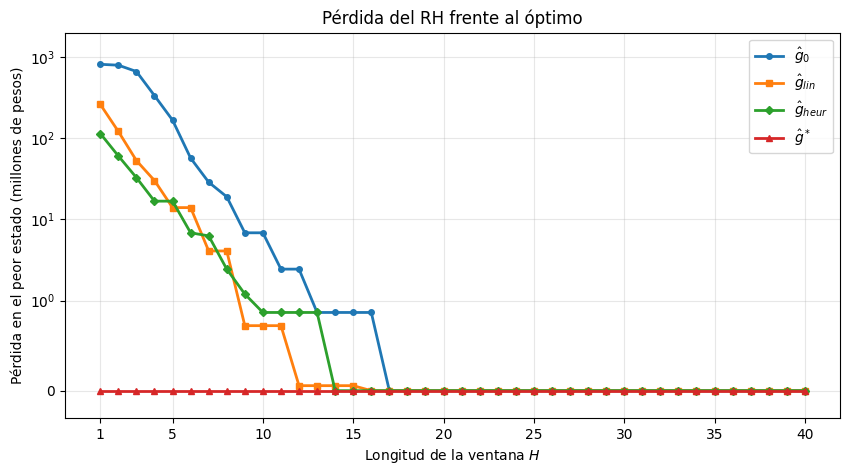

In [9]:
marcadores = ["o", "s", "D", "^"]

plt.figure(figsize=(10, 5))

for indice_terminal in range(len(valores_terminales)):

    plt.plot(
        HORIZONTES,
        perdidas[indice_terminal, :],
        marker=marcadores[indice_terminal],
        markersize=4,
        linewidth=2,
        label=etiquetas_terminales[indice_terminal]
    )

plt.yscale("symlog", linthresh=1)
plt.ylim(-0.3, 2000)
plt.xticks([1, 5, 10, 15, 20, 25, 30, 35, 40])

plt.xlabel("Longitud de la ventana $H$")
plt.ylabel("Pérdida en el peor estado (millones de pesos)")
plt.title("Pérdida del RH frente al óptimo")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

**Lectura de la Figura 1.**

- **Con $\hat g_0$ la pérdida baja de forma gradual:** 816 millones con $H=1$, 167 con $H=5$, 6.8 con $H=10$ y **exactamente cero desde $H=17$**, cuando la política RH ya es la óptima. El crecimiento lento del banco hace que la ventana tenga que ser larga para "ver" las consecuencias de sobrepescar.
- **Un mejor $\hat g$ reduce mucho la pérdida con ventanas cortas.** Con $H=1$ las pérdidas son 816, 262, 115 y 0 para $\hat g_0$, $\hat g_{\mathrm{lin}}$, $\hat g_{\mathrm{heur}}$ y $\hat g^*$. Con $\hat g^*$ el RH es óptimo para todo $H$.
- **Ventana y función terminal se sustituyen.** Para que la pérdida sea menor que el 1 % del valor óptimo (unos 7.9 millones) se necesita $H=9$ con $\hat g_0$, $H=7$ con $\hat g_{\mathrm{lin}}$, $H=6$ con $\hat g_{\mathrm{heur}}$ y $H=1$ con $\hat g^*$.
- **Llegar a pérdida exactamente cero exige ventanas parecidas** con las tres funciones no ideales (17, 16 y 14), porque las últimas diferencias son de menos de un millón.
- **$\hat g_{\mathrm{lin}}$ y $\hat g_{\mathrm{heur}}$ se alternan.** $\hat g_{\mathrm{heur}}$ pierde mucho menos con ventanas muy cortas, pero con $H=5$ y entre $H=9$ y $H=13$ $\hat g_{\mathrm{lin}}$ pierde un poco menos.

### 🎨 Figura 2 — Forma de las funciones terminales

- **Eje horizontal:** stock $s$ al final de la ventana.
- **Eje vertical:** valor relativo, $\hat g(s)-\hat g(0)$, en millones de pesos. Se resta $\hat g(0)$ porque sumar una constante no cambia las decisiones.
- **Línea gris gruesa:** $V^*(s)-V^*(0)$, la forma que $\hat g$ debería tener.

La **pendiente** de cada curva es lo que la ventana cree que vale una tonelada más en el agua. Si la pendiente de $\hat g$ es menor que la de $V^*$, el RH pesca de más; si es mayor, pesca de menos.

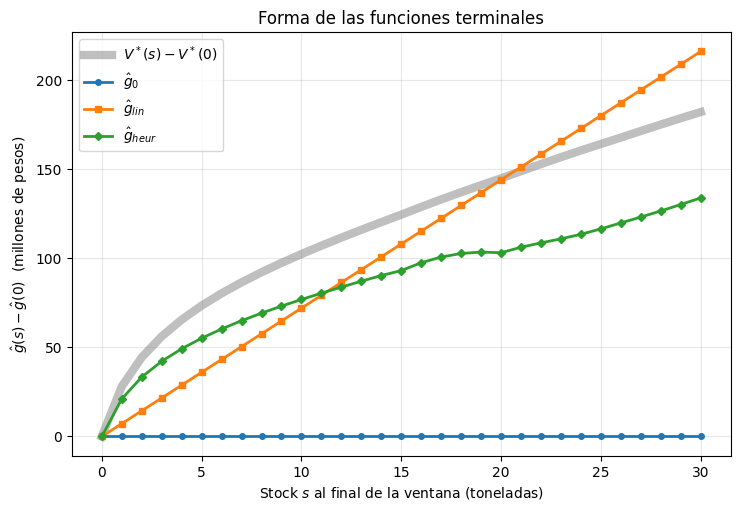

Valor de una tonelada más, ĝ(s+1) - ĝ(s), para s = 0, 5, 10, 15, 20, 25:
ĝ_0 : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
ĝ_lin : [7.2, 7.2, 7.2, 7.2, 7.2, 7.2]
ĝ_heur : [21.1, 5.2, 3.5, 4.4, 3.1, 3.3]
ĝ* : [28.1, 6.9, 4.7, 4.4, 4.0, 3.6]


In [10]:
plt.figure(figsize=(8.5, 5.5))

plt.plot(
    STOCKS,
    valor_optimo - valor_optimo[0],
    color="gray",
    alpha=0.5,
    linewidth=6,
    label="$V^*(s) - V^*(0)$"
)

# Las tres funciones no ideales (ĝ* coincide con la línea gris).
for indice_terminal in range(3):

    forma = valores_terminales[indice_terminal] - valores_terminales[indice_terminal][0]

    plt.plot(
        STOCKS,
        forma,
        marker=marcadores[indice_terminal],
        markersize=4,
        linewidth=2,
        label=etiquetas_terminales[indice_terminal]
    )

plt.xlabel("Stock $s$ al final de la ventana (toneladas)")
plt.ylabel("$\\hat g(s) - \\hat g(0)$  (millones de pesos)")
plt.title("Forma de las funciones terminales")
plt.grid(alpha=0.3)
plt.legend(loc="upper left")

plt.show()


print("Valor de una tonelada más, ĝ(s+1) - ĝ(s), para s = 0, 5, 10, 15, 20, 25:")

for indice_terminal in range(len(valores_terminales)):

    fila = []

    for stock in range(0, 26, 5):

        fila.append(round(float(
            valores_terminales[indice_terminal][stock + 1]
            - valores_terminales[indice_terminal][stock]
        ), 1))

    print(nombres_terminales[indice_terminal], ":", fila)

**Lectura de la Figura 2.**

- **El valor óptimo es cóncavo.** Con la bahía casi vacía, una tonelada más vale unos 28 millones: es la diferencia entre que el banco se recupere o no. Con mucho stock, una tonelada más vale apenas 4 millones.
- **$\hat g_0$ es plana:** la ventana cree que dejar peces en el agua no sirve de nada y pesca todo lo que da ganancia inmediata.
- **$\hat g_{\mathrm{lin}}$ tiene la misma pendiente (7.2) en todos los stocks.** Con poco stock **subvalora** los peces (7.2 frente a 28) y pesca de más justo donde es más peligroso; con mucho stock los **sobrevalora** (7.2 frente a 4) y pesca de menos.
- **$\hat g_{\mathrm{heur}}$ tiene la curvatura correcta:** una tonelada más vale 21 con la bahía vacía y entre 3 y 5 con la bahía llena. Su nivel es más bajo que el de $V^*$ porque la regla es peor que la política óptima, pero el nivel no afecta las decisiones.

La regla "dejar 15 toneladas", usada directamente, pierde unos 244 millones. Usada como función terminal, permite que una ventana de 6 temporadas quede a menos del 1 % del óptimo. Una regla mediocre puede dar un buen $\hat g$ si capta la idea correcta: los primeros peces valen mucho más que los últimos. Mejorar una política base mirando hacia adelante es justamente la idea del método de **Rollout**, que se ve la próxima semana.

---
## Resumen

| Pregunta | Respuesta en Bahía Azul |
|:---|:---|
| ¿Qué hace el RH más miope? | Con $H=1$ y $\hat g\equiv 0$ sobrepesca y agota la bahía: pierde más de 800 millones. |
| ¿Qué $H$ hace falta con $\hat g\equiv 0$? | $H=9$ para perder menos del 1 %; $H=17$ para la política óptima. |
| ¿Qué debería aproximar $\hat g$? | La forma de $V^*$: cuánto vale una tonelada más en el agua. Su nivel no importa. |
| ¿Compensa un buen $\hat g$ una ventana corta? | Sí: con $\hat g_{\mathrm{heur}}$ basta $H=6$ para perder menos del 1 %; con $\hat g^*$, $H=1$ da la política óptima. |

---
## Ejercicio abierto — Mantenimiento de un compresor

Una planta opera un compresor indefinidamente, con factor de descuento $\gamma=0.99$ por semana. Al inicio de cada semana observa su **nivel de desgaste** $w\in\{0,1,\dots,10\}$; el nivel 10 significa que el compresor está **averiado**.

Acciones:

| Acción | Efecto | Costo de la acción |
|:---:|:---|:---:|
| `"0"` operar | se opera con el desgaste actual | 0 |
| `"1"` mantenimiento | el desgaste baja a $\max(w-3,\,0)$ y luego se opera | 20 |
| `"2"` reemplazar | el desgaste pasa a 0 y luego se opera | 80 |

Si se opera con desgaste $v<10$, la semana deja un ingreso de $30-2v$ y el desgaste sube en 0, 1 o 2 niveles con probabilidades $0.4$, $0.4$ y $0.2$ (sin pasar de 10). Si se opera averiado ($v=10$), la semana cuesta 50 y el compresor sigue averiado. El mantenimiento no repara una avería por completo: desde $w=10$ deja el desgaste en 7.

### Actividades

1. Construya $R$ y $P$ con ciclos explícitos y sin definir funciones. Verifique sus resultados con la celda de referencia.
2. Resuelva el problema con `dtmdp` (VI) y calcule el valor exacto de la política óptima con el sistema lineal.
3. Calcule la política RH con $H\in\{1,2,5,10,20\}$ y $\hat g\equiv 0$, resolviendo la ventana con `dtsdp`, y evalúela con el sistema lineal. ¿Qué hace RH-1? ¿Por qué?
4. Construya dos funciones terminales más: $\hat g_{\mathrm{lin}}(w)=-\theta w$ con un $\theta$ que usted justifique, y el valor exacto de la heurística "reemplazar cuando $w\ge 7$, operar en otro caso".
5. Reproduzca la Figura 1: pérdida exacta en función de $H$ para cada $\hat g$.
6. ¿Con qué combinación de $H$ y $\hat g$ se obtiene la política óptima con el menor esfuerzo de cómputo?

### Uso crítico de IA

Antes de pedir código a una IA, calcule y guarde valores de referencia.

El prompt debe exigir:

- ciclos explícitos;
- nombres descriptivos;
- no definir funciones;
- no usar `zip`;
- no usar `enumerate`;
- no usar comprensiones de listas o diccionarios;
- no usar funciones `lambda`;
- no usar `axis`;
- resolver todos los MDP con `jmarkov` (sin VI ni backward induction programados a mano);
- calcular el valor de cada política con el sistema lineal $(I-\gamma P^\pi)V^\pi=r^\pi$.

Ejemplo de prompt:

```text
Resuelve el problema de mantenimiento del compresor descrito en el notebook,
en horizonte infinito con gamma = 0.99.

Mantén el mismo estilo de programación del curso:
- usa ciclos for explícitos;
- no definas funciones;
- no uses zip, enumerate, comprensiones, lambda ni axis;
- separa estados y acciones;
- redondea las matrices de transición a 12 decimales antes de pasarlas a jmarkov;
- resuelve el problema con dtmdp (value_iteration);
- resuelve la ventana de RH con dtsdp, agregando una época terminal
  ficticia cuyo retorno sea ĝ(s) para cualquier acción;
- nombra las acciones con un solo carácter ("0", "1", "2"), porque dtsdp
  guarda las decisiones como texto de un carácter;
- calcula el valor de cada política resolviendo (I - gamma P) V = r.

Antes de continuar, compara las filas de R y de P con los valores de referencia del notebook.
```

In [11]:
# Checkpoint para el ejercicio abierto: filas de referencia de R y P.

NIVEL_AVERIA = 10
NUMERO_NIVELES = NIVEL_AVERIA + 1

INCREMENTOS_DESGASTE = [0, 1, 2]
PROBABILIDADES_INCREMENTO = [0.4, 0.4, 0.2]

COSTOS_ACCION = [0, 20, 80]

retornos_compresor_referencia = np.zeros((NUMERO_NIVELES, 3))
transicion_operar_referencia = np.zeros((NUMERO_NIVELES, NUMERO_NIVELES))

for desgaste in range(NUMERO_NIVELES):

    for accion in range(3):

        # Desgaste con el que se opera después de la acción.
        if accion == 0:
            desgaste_operacion = desgaste
        elif accion == 1:
            desgaste_operacion = max(desgaste - 3, 0)
        else:
            desgaste_operacion = 0

        if desgaste_operacion == NIVEL_AVERIA:
            ingreso = -50
        else:
            ingreso = 30 - 2 * desgaste_operacion

        retornos_compresor_referencia[desgaste, accion] = ingreso - COSTOS_ACCION[accion]

        if accion == 0:

            if desgaste_operacion == NIVEL_AVERIA:

                transicion_operar_referencia[desgaste, NIVEL_AVERIA] = 1.0

            else:

                for indice in range(len(INCREMENTOS_DESGASTE)):

                    desgaste_siguiente = min(
                        NIVEL_AVERIA,
                        desgaste_operacion + INCREMENTOS_DESGASTE[indice]
                    )

                    transicion_operar_referencia[desgaste, desgaste_siguiente] = (
                        transicion_operar_referencia[desgaste, desgaste_siguiente]
                        + PROBABILIDADES_INCREMENTO[indice]
                    )

print("Filas de R para w = 0, 5, 10 (operar, mantenimiento, reemplazar):")
print(retornos_compresor_referencia[[0, 5, 10], :])

print("\nFila de P desde w = 9, operar:")
print(transicion_operar_referencia[9, :])

Filas de R para w = 0, 5, 10 (operar, mantenimiento, reemplazar):
[[ 30.  10. -50.]
 [ 20.   6. -50.]
 [-50.  -4. -50.]]

Fila de P desde w = 9, operar:
[0.  0.  0.  0.  0.  0.  0.  0.  0.  0.4 0.6]


---
<small>Universidad de los Andes · Departamento de Ingeniería Industrial · Modelos de Decisión en el Tiempo</small>